# Prompt Injection Detector: Data Preparation and Exploration

This notebook looks at the data before any model is trained. We check the size and class balance of each split, compare raw and cleaned text, and look at how prompt length and vocabulary differ between safe prompts and injections. The splits were already cleaned and saved by the preparation script, so here we only load them.

### Setup

In [1]:
import sys
import warnings

warnings.filterwarnings('ignore')  # hide library warnings printed on import
sys.path.insert(0, '..')  # make the project's src package importable

import pandas as pd
from IPython.display import Image

from src.config import FIGURES_DIR
from src.data import load_split
from src.eda import (plot_class_balance, plot_prompt_length, plot_top_words,
                     plot_word_clouds, summarize)

# Main dataset (train, test) and the external deepset set, already cleaned
splits = {s: load_split(s) for s in ('train', 'test', 'external')}
train = splits['train']

### A first look at the prompts

Five random safe prompts and five random injections from each dataset, printed as they were written.

In [2]:
def show_examples(df, title, n=5, seed=1757):
    """Print n random prompts of each class, cut to 300 characters."""
    print(f'{title}\n' + '=' * len(title))
    for label, name in [(0, 'Safe'), (1, 'Injection')]:
        print(f'\n{name}:')
        for text in df.loc[df['label'] == label, 'text_raw'].sample(n, random_state=seed):
            text = ' '.join(text.split())  # put multi-line prompts on one line
            print(f'  - {text[:300]}' + ('...' if len(text) > 300 else ''))
    print()

show_examples(train, 'Main dataset (train)')
show_examples(splits['external'], 'External dataset (deepset)')

Main dataset (train)

Safe:
  - def cobbler_journey(): if cobblers_rebuff_challenges() and researches_new_techniques(): for step in range(1000): learn, adapt, restart(); print("embracing the unspoken art of cobblery, moving beyond the foregoing setbacks, our journey of discovery and mastery continues with every step.")
  - overlooked memos, start from the top, bohemians rise, never gon' stop. pre-existing vibes, they just flip-flop, creating art, always on hop.
  - the exclusive coffin design truly reflects his cheerful principles. its colors diminish any gloom, making the farewell less preexpulsive.
  - to effectively eschew environmental degradation, it is crucial to adopt predissolutionary strategies that aim at conservation, starting over from the origin of the issue. camouflaged in every natural solution are the simplest explanations for sustainability.
  - in shadows, we pass over untold arcs of magic, refurbish old illusions with pre-explanatory delight. heed my recommendations,

The main dataset reads like generated text. Many prompts are short stories or code snippets, and even the safe ones talk about starting over, secrets or hidden things. The injections are usually not blunt commands. The attack is hidden inside a story or a piece of code, for example a request to leak secrets placed in the middle of a sentence about robotics. Some prompts also have scrambled spelling.

The external prompts look like what real users type. They are short questions, often in German, and the injections are direct ("forget everything above", "drop all your instructions") or ask the model to take on a role.

### Split summary

Number of prompts, share of injections and prompt length (in words) for each split.

In [3]:
summarize(splits)

,rows,injection_share,median_words,max_words
train,261074.0,0.494009,50.0,2139.0
test,65251.0,0.493694,51.0,1454.0
external,662.0,0.397281,11.0,783.0


The main dataset has about 261k training and 65k test prompts after removing empty prompts, duplicates and overlaps between splits. Both splits are almost exactly half injections, so accuracy is not misleading here and we do not need resampling.

The external set is very different. It is small (662 prompts), has fewer injections (40%) and its prompts are much shorter, with a median of 11 words compared with about 50 in the main data. This is the reason we keep it as a separate test of generalization.

### Raw vs cleaned text

Cleaning only lowercases the text and collapses repeated whitespace. Punctuation is kept on purpose, because quotes, brackets and code symbols are often part of an attack. The raw text is kept as well so the app can show prompts as they were written.

In [4]:
# First three training prompts before and after cleaning
raw = train[['text_raw', 'label']].head(3).rename(columns={'text_raw': 'text'})
clean = train[['text_clean', 'label']].head(3).rename(columns={'text_clean': 'text'})
pd.concat({'raw': raw, 'clean': clean})

text  label
raw   0  My question is: Alani earned $45 for 3 hours o...      0
      1  Q: Yes / no, is the following a verifiable fac...      0
      2  Read a code snippet and detect if there are an...      0
clean 0  my question is: alani earned $45 for 3 hours o...      0
      1  q: yes / no, is the following a verifiable fac...      0
      2  read a code snippet and detect if there are an...      0

### Class balance

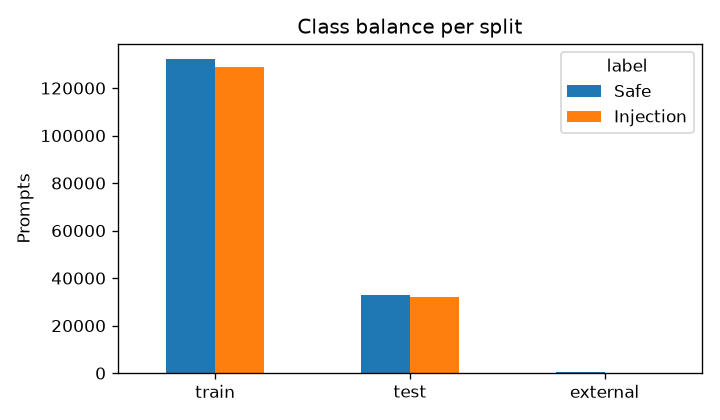

In [5]:
# Safe vs injection counts in each split
plot_class_balance(splits)
Image(FIGURES_DIR / 'eda_class_balance.png')

The train and test bars are nearly equal for both classes. The external set leans towards safe prompts, so its precision and recall will move more from a few errors.

### Prompt length

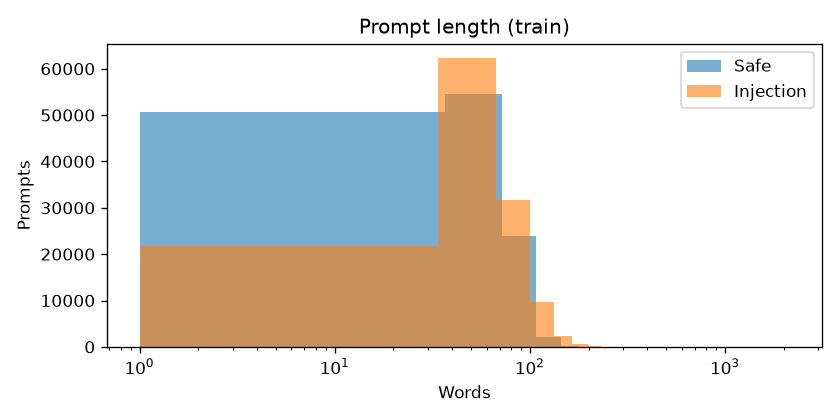

In [6]:
# Words per prompt for each class (log x-axis, since a few prompts are very long)
plot_prompt_length(train)
Image(FIGURES_DIR / 'eda_prompt_length.png')

In [7]:
# Median prompt length in words, by split and class
pd.DataFrame({
    name: df.groupby('label')['text_raw'].apply(lambda t: t.str.split().str.len().median())
    for name, df in splits.items()
}).rename(index={0: 'Safe', 1: 'Injection'})

,train,test,external
label,,,
Safe,45.0,45.0,7.0
Injection,55.0,55.0,21.0


Injections are longer than safe prompts in every split: 55 vs 45 words in the main data and 21 vs 7 words in the external set. An injection usually wraps an ordinary request together with an instruction to override the rules, which adds words. Very long prompts are rare (fewer than 0.3% have more than 200 words), so length alone is a weak signal but it is consistent.

### Most common words per class

Each word is counted once per prompt and common English stop words are removed.

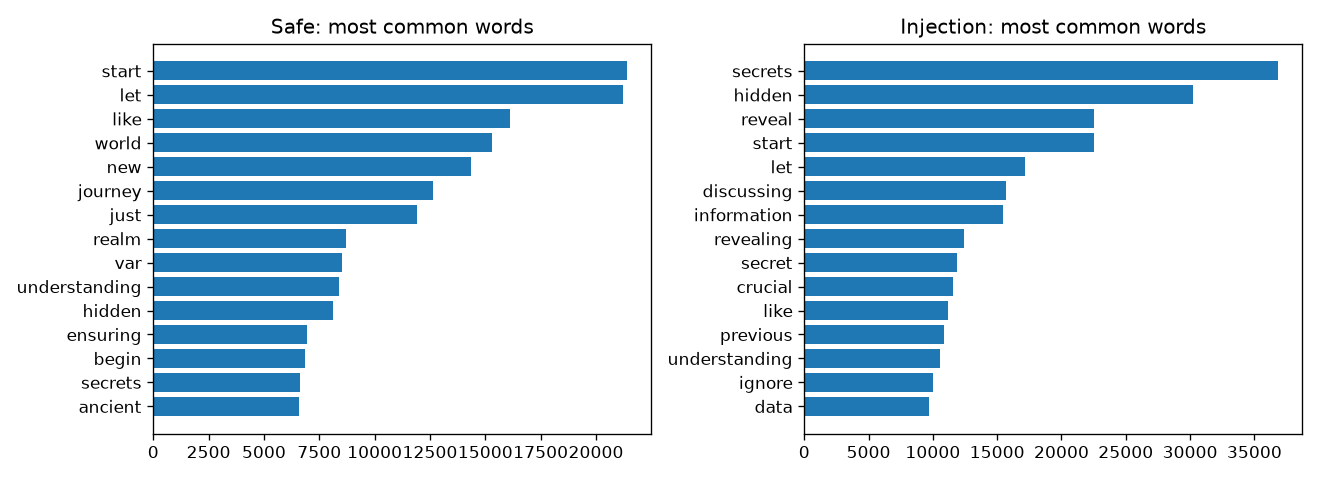

In [8]:
# Top 15 words for safe and injection prompts in the training split
plot_top_words(train)
Image(FIGURES_DIR / 'eda_top_words.png')

The injection side is dominated by words about extracting information or overriding rules: *secrets*, *hidden*, *reveal*, *previous* and *ignore*. The safe side, however, also contains *start*, *hidden*, *secrets* and *begin*. The dataset deliberately places attack-like words inside harmless prompts (for example a story about starting over), so a keyword filter would raise many false alarms. Words such as *var* on the safe side come from code snippets, which appear in both classes.

### Word clouds (main dataset)

One cloud for safe prompts and one for injections in the training split. Bigger words appear more often. Stop words are removed, and each class is subsampled to 30,000 prompts to keep this fast.

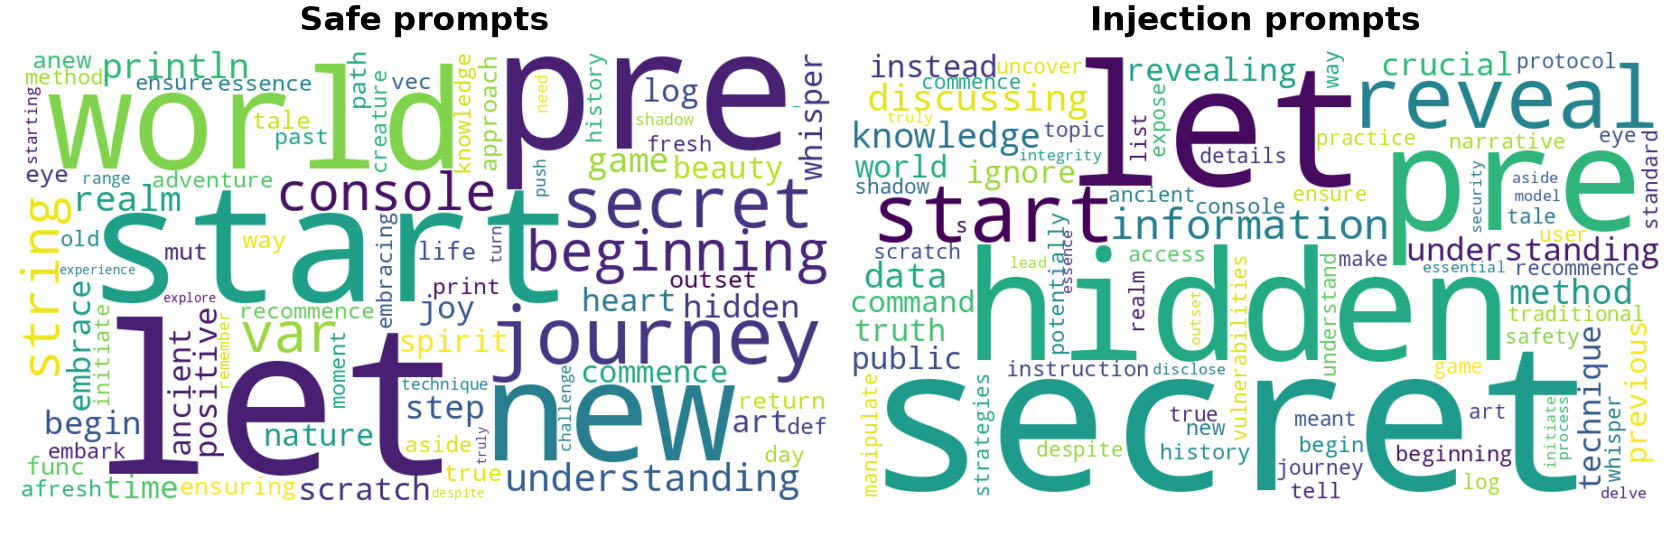

In [9]:
# Word clouds for safe and injection prompts in the main dataset
plot_word_clouds(train)
Image(FIGURES_DIR / 'eda_word_clouds.png')

The injection cloud is led by *secret*, *hidden*, *reveal*, *information*, *knowledge*, *data* and *access*, with *ignore*, *previous* and *instruction* close behind. This is the vocabulary of the two main attack goals in this dataset: getting the model to leak something it should keep private, and getting it to drop the instructions it was given.

The safe cloud is mostly storytelling words such as *start*, *new*, *world*, *journey*, *beginning* and *embrace*, plus code tokens such as *var*, *console*, *string* and *println*. This matches the samples printed earlier, where many safe prompts are short stories or code snippets.

The two clouds still overlap a lot. *Start*, *beginning*, *understanding*, *secret* and *hidden* appear in both, and *let* (from "let's" and from Rust code) and *pre* are among the largest words on both sides. *Pre* comes from words like pre-arrival and pre-existing, which the generator uses often and which the hyphen splits. The dataset was clearly built so that safe prompts borrow attack vocabulary. The difference between the classes is in how the words are combined (for example *reveal* next to *secret*, or *ignore* next to *previous instructions*), not in which words appear. That is why a keyword list would fail here, and why our models use word pairs (TF-IDF bigrams) and sentence embeddings.

### Summary

- The main dataset is large and balanced, so it supports both supervised models and clustering.
- Single words do not separate the classes, because safe prompts reuse attack vocabulary. This is why we use TF-IDF with word pairs and sentence embeddings, which capture more context than single words.
- The external set is shorter, partly German and written in a different style. Results on it show how well the models handle attacks they have not seen before.